# 07 · Publication figures

All figures are drawn from the result tables written by notebooks 01–06; no estimate is computed or edited here. Every figure is saved as vector PDF, 600 dpi PNG and LZW-compressed TIFF, together with the data it plots (`../results/figures/data/`).

**Style.** One style for the paper: Arial, three font sizes (8/7/6 pt), Okabe–Ito colours with one meaning each (blue = N2, the primary reference; vermillion = N1; green = N2 clean; other references in SI), purple = excess and orange = deficit co-occurrence (`PuOr`, centred at zero), red/blue for frequency change (`RdBu_r`, centred at zero), bold panel letters, units on every axis, white background, no titles inside figures (captions carry the context).

The Figure 4(b) bars show the relative reduction in model discrepancy. The raw deviance and dispersion-adjusted Pearson measures use the archived column names `frequency_share_raw` and `frequency_share_dispersion_floor`.

In [1]:
import os, json, itertools
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import TwoSlopeNorm

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
TAB = ROOT / "results" / "tables"; AGG = ROOT / "results" / "aggregates"
FIG = ROOT / "results" / "figures"; FDATA = FIG / "data"; FDATA.mkdir(parents=True, exist_ok=True)
mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 6, "ytick.labelsize": 6, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.facecolor": "white", "figure.facecolor": "white", "legend.frameon": False})
OI = {"blue": "#0072B2", "vermillion": "#D55E00", "green": "#009E73", "sky": "#56B4E9", "orange": "#E69F00",
      "purple": "#CC79A7", "yellow": "#F0E442", "black": "#000000", "grey": "#8C8C8C"}
REF_COLOR = {"N2": OI["blue"], "N1": OI["vermillion"], "N2_clean": OI["green"], "N2_allmedia": OI["purple"],
             "N2_order": OI["sky"], "N1_k2": OI["orange"]}
REF_LABEL = {"N2": "Context and field (N2)", "N1": "Month (N1)", "N2_clean": "N2, generic codes removed",
             "N2_allmedia": "N2, all media", "N2_order": "N2, order preserved", "N1_k2": "N1, two-tactic actions"}
YEARS = np.arange(2008, 2025)
PAIRS = np.array(list(itertools.combinations(range(1, 36), 2)))
dic = pd.read_csv(TAB / "tactic_dictionary.csv").set_index("code")
FAM_ORDER = ["A Peaceful I", "B Peaceful II", "C Artistic", "D Disruptive", "E Self-destructive", "F Violent"]
FAM_BOUNDS = [6, 14, 17, 24, 26]          # last code of families A-E
SHORT = {5: "Petition or fund collection", 7: "Press conference", 8: "Assembly or debate", 15: "Performance (participants)",
         16: "Performance (artists)", 23: "Interrupting authorities", 26: "Self-endangering act", 32: "Clash with counter-protesters",
         33: "Attack on police", 34: "Attack on bystanders", 35: "Hostage taking"}
short = lambda c: SHORT.get(int(c), dic.loc[int(c), "label_en"])

def panel_letter(ax, letter, x=-0.14, y=1.03):
    ax.text(x, y, letter, transform=ax.transAxes, fontsize=10, fontweight="bold", va="bottom", ha="left")

def layout_problems(fig):
    # render-then-verify: text that overlaps other text, crosses a spine or leaves the canvas
    fig.canvas.draw(); r = fig.canvas.get_renderer()
    pool = {t for ax in fig.axes for axis in (ax.xaxis, ax.yaxis) for tick in axis.majorTicks + axis.minorTicks for t in (tick.label1, tick.label2)}
    own = {ax: set(ax.get_xticklabels(which="both") + ax.get_yticklabels(which="both")) for ax in fig.axes}
    inside = lambda axis, tick: min(axis.get_view_interval()) - 1e-9 <= tick.get_loc() <= max(axis.get_view_interval()) + 1e-9
    active = {t for ax in fig.axes for axis in (ax.xaxis, ax.yaxis) for tick in axis.get_major_ticks() + axis.get_minor_ticks()
              if inside(axis, tick) for t in (tick.label1, tick.label2) if t in own[ax]}
    texts = [(t, t.get_window_extent(r)) for t in fig.findobj(mpl.text.Text)
             if t.get_visible() and t.get_text().strip() and (t not in pool or t in active)]
    spines = [(s, s.get_window_extent(r)) for ax in fig.axes for s in ax.spines.values() if s.get_visible()]
    probs = [f"{a.get_text()[:30]!r} overlaps {b.get_text()[:30]!r}" for i, (a, ba) in enumerate(texts) for b, bb in texts[i + 1:] if ba.overlaps(bb)]
    probs += [f"{t.get_text()[:30]!r} crosses a spine" for t, bt in texts for s, bs in spines if bt.overlaps(bs) and t not in own[s.axes]]
    probs += [f"{t.get_text()[:30]!r} leaves the canvas" for t, bt in texts
              if bt.x0 < fig.bbox.x0 or bt.y0 < fig.bbox.y0 or bt.x1 > fig.bbox.x1 or bt.y1 > fig.bbox.y1]
    return probs

def export_source_table(frame, name, index=False):
    display(frame)
    frame.to_csv(FDATA / name, index=index)

def save(fig, name):
    probs = layout_problems(fig)
    print(name, "layout check:", "ok" if not probs else probs)
    display(fig)
    for ext, kw in [("pdf", {}), ("png", {"dpi": 600}), ("tiff", {"dpi": 600, "pil_kwargs": {"compression": "tiff_lzw"}})]:
        fig.savefig(FIG / f"{name}.{ext}", **kw)
    plt.close(fig)
    print("saved", name)

## Fig 1 · What changed: volume, list size and tactic frequencies

Fig1 layout check: ok
saved Fig1


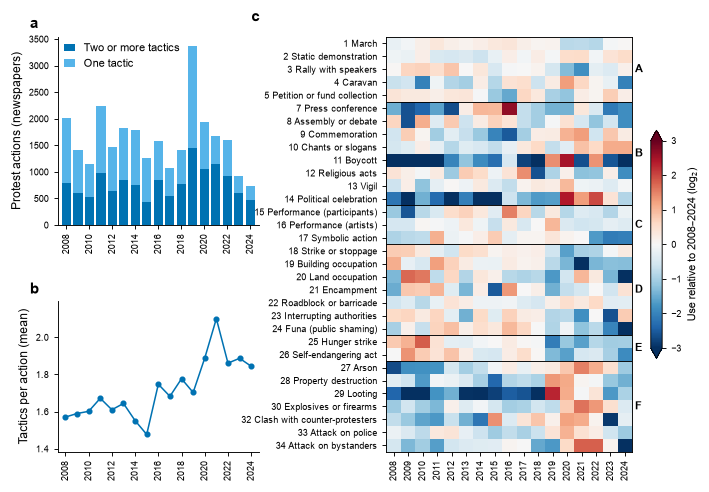

In [2]:
cov = pd.read_csv(TAB / "annual_coverage.csv"); cov = cov[cov["sample"] == "newspapers"].set_index("year")
marg = pd.read_csv(TAB / "tactic_counts_by_year.csv").set_index("year"); marg.columns = marg.columns.astype(int)
tot = marg.sum(); keep = [c for c in range(1, 36) if tot[c] >= 50]
expected = np.outer(cov.actions, tot[keep] / cov.actions.sum())
rel = np.log2((marg[keep].to_numpy() + 0.5) / (expected + 0.5))         # years x tactics
fig1_data = pd.DataFrame(rel, index=YEARS, columns=keep)
export_source_table(fig1_data, "fig1_relative_frequency.csv", index=True)
export_source_table(cov[["actions", "multi_tactic", "mean_k"]], "fig1_volume.csv", index=True)

fig = plt.figure(figsize=(7.5, 4.9))
gs = GridSpec(2, 2, figure=fig, width_ratios=[1, 1.55], height_ratios=[1.25, 1], wspace=0.5, hspace=0.45)
ax = fig.add_subplot(gs[0, 0])
single = cov.actions - cov.multi_tactic
ax.bar(YEARS, cov.multi_tactic, color=OI["blue"], width=0.8, label="Two or more tactics")
ax.bar(YEARS, single, bottom=cov.multi_tactic, color=OI["sky"], width=0.8, label="One tactic")
ax.set_ylabel("Protest actions (newspapers)"); ax.set_xticks(YEARS[::2]); ax.tick_params(axis="x", rotation=90)
ax.legend(loc="upper left", handlelength=1, borderaxespad=0.2); ax.margins(x=0.02)
panel_letter(ax, "a")
ax = fig.add_subplot(gs[1, 0])
ax.plot(YEARS, cov.mean_k, "o-", color=OI["blue"], ms=3, lw=1)
ax.set_ylabel("Tactics per action (mean)"); ax.set_xticks(YEARS[::2]); ax.tick_params(axis="x", rotation=90)
ax.margins(x=0.04, y=0.15)
panel_letter(ax, "b")
ax = fig.add_subplot(gs[:, 1])
norm = TwoSlopeNorm(vcenter=0, vmin=-3, vmax=3)
im = ax.imshow(np.clip(rel.T, -3, 3), aspect="auto", cmap="RdBu_r", norm=norm, interpolation="none")
ax.set_xticks(range(len(YEARS)), YEARS, rotation=90); ax.set_yticks(range(len(keep)), [f"{c} {short(c)}" for c in keep])
fam_of = [dic.loc[c, "family_label"] for c in keep]
for i in range(1, len(keep)):
    if fam_of[i] != fam_of[i - 1]:
        ax.axhline(i - 0.5, color="k", lw=0.6)
for fam in FAM_ORDER:
    idx = [i for i, f in enumerate(fam_of) if f == fam]
    if idx:
        ax.text(len(YEARS) - 0.3, np.mean(idx), fam.split(" ", 1)[0], va="center", ha="left", fontsize=7, fontweight="bold")
ax.spines[["top", "right"]].set_visible(True)
cb = fig.colorbar(im, ax=ax, shrink=0.55, pad=0.06, extend="both")
cb.set_label("Use relative to 2008–2024 (log$_2$)", fontsize=7); cb.ax.tick_params(labelsize=6)
panel_letter(ax, "c", x=-0.55)
save(fig, "Fig1")

## Fig 2 · The combination structure over 2008–2024 (N2)

Fig2 layout check: ok
saved Fig2


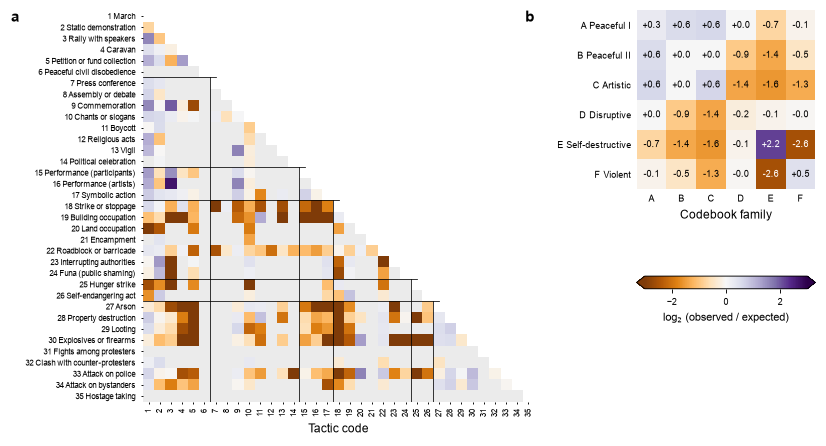

In [3]:
pairs = pd.read_csv(TAB / "pairs_full_period_N2.csv")
fam = pd.read_csv(TAB / "family_structure.csv"); fam = fam[fam.reference == "N2"]
M = np.full((35, 35), np.nan)
for _, r in pairs.iterrows():
    if r.evaluable:
        M[r.code_j - 1, r.code_i - 1] = r.log2_ratio          # lower triangle
export_source_table(pairs[pairs.evaluable], "fig2a_pair_matrix_N2.csv")
F = pd.DataFrame(np.nan, index=FAM_ORDER, columns=FAM_ORDER)
for _, r in fam.iterrows():
    F.loc[r.family_a, r.family_b] = F.loc[r.family_b, r.family_a] = r.log2_ratio
export_source_table(F, "fig2b_family_matrix_N2.csv", index=True)

fig = plt.figure(figsize=(7.5, 4.6))
gs = GridSpec(2, 2, figure=fig, width_ratios=[3.5, 1.6], height_ratios=[2.5, 1], wspace=0.36, hspace=0.25, left=0.17, right=0.985, bottom=0.1, top=0.97)
ax = fig.add_subplot(gs[:, 0]); ax.set_anchor("N")
norm = TwoSlopeNorm(vcenter=0, vmin=-3, vmax=3)
grey = np.where(np.tril(np.ones((35, 35)), -1) > 0, 1.0, np.nan); grey[~np.isnan(M)] = np.nan
ax.imshow(grey, cmap=mpl.colors.ListedColormap(["#EBEBEB"]), interpolation="none")
im = ax.imshow(np.clip(M, -3, 3), cmap="PuOr", norm=norm, interpolation="none")
for b in FAM_BOUNDS:
    ax.plot([-0.5, b + 0.5 - 1 + 1 - 0.5], [b - 0.5, b - 0.5], color="k", lw=0.5)
    ax.plot([b - 0.5, b - 0.5], [b - 0.5, 34.5], color="k", lw=0.5)
ax.set_xticks(range(35), range(1, 36), fontsize=5, rotation=90); ax.set_yticks(range(35), [f"{c} {short(c)}" for c in range(1, 36)], fontsize=5)
ax.tick_params(length=1.5)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel("Tactic code")
fig.text(0.01, 0.97, "a", fontsize=10, fontweight="bold", va="top")
ax = fig.add_subplot(gs[0, 1]); ax.set_anchor("N")
im2 = ax.imshow(F.to_numpy(), cmap="PuOr", norm=norm)
for i in range(6):
    for j in range(6):
        v = F.iloc[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 1.6 else "black")
fam_letters = ["A", "B", "C", "D", "E", "F"]
ax.set_xticks(range(6), fam_letters); ax.set_yticks(range(6), FAM_ORDER)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
ax.set_xlabel("Codebook family")
fig.canvas.draw(); pb = ax.get_position()
fig.text(pb.x0 - 0.135, 0.97, "b", fontsize=10, fontweight="bold", va="top")
cax = fig.add_axes([pb.x0, 0.42, pb.width, 0.025])
cb = fig.colorbar(im, cax=cax, orientation="horizontal", extend="both")
cb.set_label("log$_2$ (observed / expected)", fontsize=7); cb.ax.tick_params(labelsize=6)
save(fig, "Fig2")

## Fig 3 · The structure recurs every year

Fig3 layout check: ok
saved Fig3


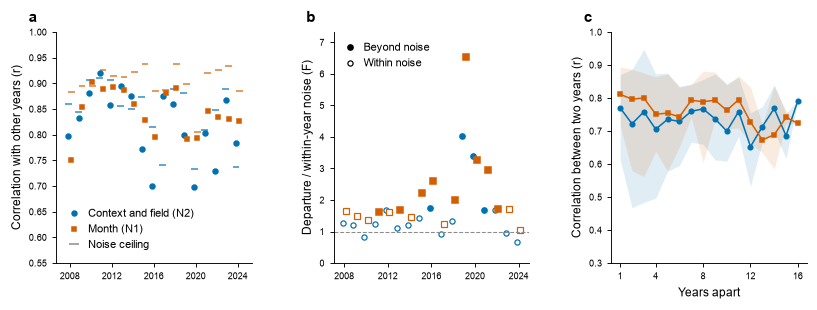

In [4]:
calib = pd.read_csv(TAB / "annual_calibration.csv")
lagp = pd.read_csv(TAB / "annual_lag_profile.csv")
Ftab = pd.read_csv(TAB / "annual_departure_F.csv")
export_source_table(calib, "fig3ab_year_vs_rest.csv")
export_source_table(lagp, "fig3c_lag_profile.csv")
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.8), gridspec_kw={"wspace": 0.42})
fig.subplots_adjust(left=0.08, right=0.99, bottom=0.15, top=0.9)
ax = axes[0]
for name, off, mk in [("N2", -0.15, "o"), ("N1", 0.15, "s")]:
    z = calib[calib.reference == name]
    ax.plot(z.year + off, z.pearson, mk, color=REF_COLOR[name], ms=3.2, label=REF_LABEL[name], zorder=3)
    ax.hlines(z.ceiling, z.year + off - 0.32, z.year + off + 0.32, color=REF_COLOR[name], lw=1.0, alpha=0.8)
ax.plot([], [], "_", color=OI["grey"], ms=7, mew=1.0, label="Noise ceiling")
ax.set_ylim(0.55, 1.0); ax.set_ylabel("Correlation with other years (r)")
ax.set_xticks(YEARS[::4]); ax.legend(loc="lower left", handlelength=1, borderaxespad=0.8)
panel_letter(ax, "a")
ax = axes[1]
for name, off, mk in [("N2", -0.15, "o"), ("N1", 0.15, "s")]:
    z = Ftab[Ftab.reference == name]; sig = z.p_holm < 0.05
    ax.plot(z.year[sig] + off, z.F[sig], mk, color=REF_COLOR[name], ms=3.4)
    ax.plot(z.year[~sig] + off, z.F[~sig], mk, mfc="white", mec=REF_COLOR[name], ms=3.4, mew=0.8)
ax.axhline(1, color=OI["grey"], lw=0.7, ls="--")
ax.set_ylabel("Departure / within-year noise (F)"); ax.set_xticks(YEARS[::4]); ax.set_ylim(0, Ftab[Ftab.reference.isin(["N2", "N1"])].F.max() * 1.12)
ax.plot([], [], "o", color="k", ms=3.4, label="Beyond noise")
ax.plot([], [], "o", mfc="white", mec="k", ms=3.4, mew=0.8, label="Within noise")
ax.legend(loc="upper left", handlelength=1, borderaxespad=0.6)
export_source_table(Ftab, "fig3b_departure_F.csv")
panel_letter(ax, "b")
ax = axes[2]
for name, mk in [("N2", "o"), ("N1", "s")]:
    z = lagp[lagp.reference == name]
    ax.fill_between(z.lag_years, z.min_pearson, z.max_pearson, color=REF_COLOR[name], alpha=0.12, lw=0)
    ax.plot(z.lag_years, z.mean_pearson, mk + "-", color=REF_COLOR[name], ms=3, lw=1, label=REF_LABEL[name])
ax.set_ylim(0.3, 1.0); ax.set_xlabel("Years apart"); ax.set_ylabel("Correlation between two years (r)")
ax.set_xticks([1, 4, 8, 12, 16])
panel_letter(ax, "c")
save(fig, "Fig3")

## Fig 4 · Strength of the combination structure and relative improvements in model fit

Fig4 layout check: ok
saved Fig4


,reference,year,phi,phi_lo,phi_hi
0,N2,2008,1.024301,0.894811,1.191837
1,N2,2009,0.986626,0.857171,1.131306
2,N2,2010,1.152488,0.989313,1.361597
3,N2,2011,1.102160,1.007335,1.205608
4,N2,2012,1.093077,0.962208,1.242401
5,N2,2013,1.031578,0.918584,1.150698
6,N2,2014,1.000725,0.883011,1.120407
7,N2,2015,0.921177,0.737176,1.133625
8,N2,2016,0.902580,0.751884,1.088355
9,N2,2017,1.030779,0.855094,1.236188


,pairs_with_expected,cells,D_M0,D_M1,D_M2,D_MA,perm_mean_D_M1,perm_mean_D_MA,perm_mean_D_M2,share_structure_constant,share_change_uniform_strength,frequency_share_raw,frequency_share_permutation_floor,excess_D_M1_over_noise,excess_D_MA_over_noise,permutations_infinite_deviance,p_perm_D_M1,p_perm_uniform_term,X2_M1,X2_MA,df_residual_M1,pooled_dispersion_within,frequency_share_dispersion_floor,F_uniform_strength,p_F_uniform_strength
reference,,,,,,,,,,,,,,,,,,,,,,,,,
N2,291,4947,14025.063912,4349.815357,4302.826010,15126.543621,5476.937429,8448.433739,5446.375260,0.689854,0.010803,0.712438,1.168779,-1127.122072,6678.109881,0,1.000,0.068,5992.015287,17029.772636,4256,1.298204,0.959420,2.262229,2.800725e-03
N1,291,4947,24067.803000,5813.877089,5510.782867,15126.543621,4852.547444,8448.433739,4758.381682,0.758438,0.052133,0.615651,0.856048,961.329646,6678.109881,0,0.001,0.001,7205.216867,17029.772636,4256,1.353185,0.871696,13.999114,1.312768e-37
N2_clean,230,4947,8805.701621,2804.648192,2772.205530,8136.939814,3549.614040,5182.328124,3515.010151,0.681496,0.011567,0.655319,1.252137,-744.965848,2954.611690,9,1.000,0.531,4706.462007,9580.544271,3200,1.284011,0.890779,1.579165,6.599931e-02


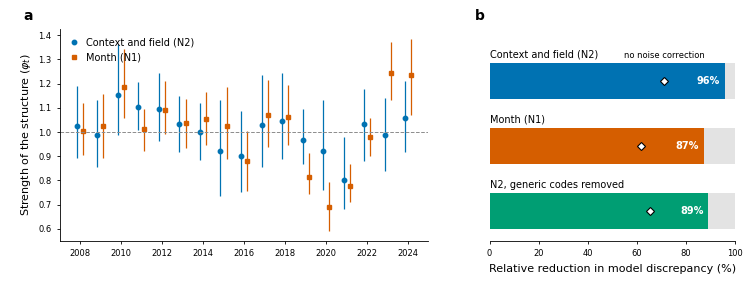

In [5]:
phit = pd.read_csv(TAB / "unidiff_phi_by_year.csv")
dec = pd.read_csv(TAB / "loglinear_decomposition.csv").set_index("reference")
export_source_table(phit, "fig4a_phi.csv")
export_source_table(dec, "fig4b_decomposition.csv", index=True)
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.9), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.2})
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.17, top=0.9)
ax = axes[0]
for name, off, mk in [("N2", -0.15, "o"), ("N1", 0.15, "s")]:
    z = phit[phit.reference == name]
    ax.vlines(z.year + off, z.phi_lo, z.phi_hi, color=REF_COLOR[name], lw=0.9)
    ax.plot(z.year + off, z.phi, mk, color=REF_COLOR[name], ms=3.2, label=REF_LABEL[name])
ax.axhline(1, color=OI["grey"], lw=0.7, ls="--")
ax.set_ylabel("Strength of the structure ($\\varphi_t$)"); ax.set_xticks(YEARS[::2])
ax.legend(loc="upper left", handlelength=1)
panel_letter(ax, "a", x=-0.1)
ax = axes[1]
refs = ["N2", "N1", "N2_clean"]
disp = [100 * dec.loc[r, "frequency_share_dispersion_floor"] for r in refs]
raw = [100 * dec.loc[r, "frequency_share_raw"] for r in refs]
y = np.arange(len(refs))[::-1]
ax.barh(y, disp, color=[REF_COLOR[r] for r in refs], height=0.55)
ax.barh(y, [100 - v for v in disp], left=disp, color="#E3E3E3", height=0.55)
ax.plot(raw, y, "D", mfc="white", mec="k", ms=4, mew=0.8)
for yy, v, r in zip(y, disp, refs):
    ax.text(v - 2, yy, f"{v:.0f}%", ha="right", va="center", fontsize=7, color="white", fontweight="bold")
    ax.text(0, yy + 0.33, REF_LABEL[r], ha="left", va="bottom", fontsize=7)
ax.text(raw[0], y[0] + 0.33, "no noise correction", ha="center", va="bottom", fontsize=6)
ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.set_xlim(0, 100); ax.set_ylim(-0.45, len(refs) - 0.2)
ax.set_xlabel("Relative reduction in model discrepancy (%)")
panel_letter(ax, "b", x=-0.06)
save(fig, "Fig4")

## Supporting figures

S1_Fig layout check: ok
saved S1_Fig


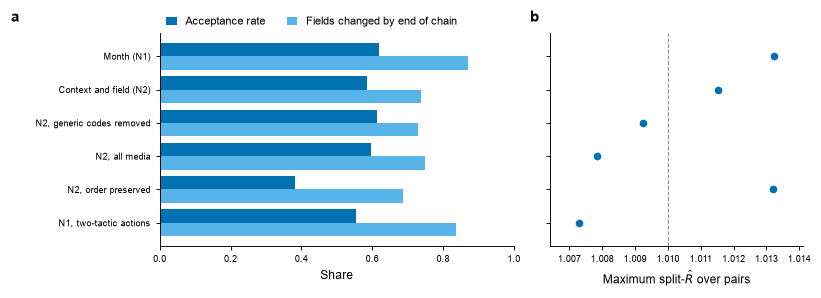

In [6]:
# S1 Fig: sampler validation
mcmc = pd.read_csv(TAB / "mcmc_diagnostics.csv")
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.8), sharey=True, gridspec_kw={"wspace": 0.12, "width_ratios": [1.4, 1]})
fig.subplots_adjust(left=0.2, right=0.98, bottom=0.17, top=0.86)
y = np.arange(len(mcmc))[::-1]
ax = axes[0]
ax.barh(y + 0.2, mcmc.acceptance_mean, 0.4, color=OI["blue"], label="Acceptance rate")
ax.barh(y - 0.2, mcmc.changed_fields_mean, 0.4, color=OI["sky"], label="Fields changed by end of chain")
ax.set_yticks(y, [REF_LABEL[s] for s in mcmc.spec]); ax.set_xlabel("Share"); ax.set_xlim(0, 1)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, handlelength=1, borderaxespad=0.2); panel_letter(ax, "a", x=-0.42, y=1.04)
ax = axes[1]
ax.plot(mcmc.rhat_max, y, "o", color=OI["blue"], ms=4)
ax.axvline(1.01, color=OI["grey"], lw=0.7, ls="--")
ax.set_xlabel("Maximum split-$\\hat{R}$ over pairs"); ax.margins(x=0.15)
panel_letter(ax, "b", x=-0.08, y=1.04)
export_source_table(mcmc, "S1_mcmc.csv")
save(fig, "S1_Fig")

S2_Fig layout check: ok
saved S2_Fig


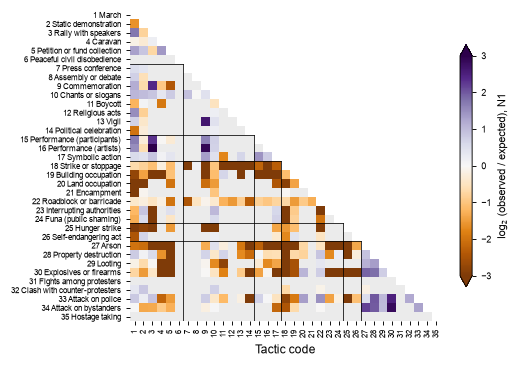

In [7]:
# S2 Fig: pair matrix under N1
pairs1 = pd.read_csv(TAB / "pairs_full_period_N1.csv")
M1 = np.full((35, 35), np.nan)
for _, r in pairs1.iterrows():
    if r.evaluable:
        M1[r.code_j - 1, r.code_i - 1] = r.log2_ratio
fig, ax = plt.subplots(figsize=(5.6, 4.6))
fig.subplots_adjust(left=0.27, right=0.9, bottom=0.1, top=0.97)
grey = np.where(np.tril(np.ones((35, 35)), -1) > 0, 1.0, np.nan); grey[~np.isnan(M1)] = np.nan
ax.imshow(grey, cmap=mpl.colors.ListedColormap(["#EBEBEB"]), interpolation="none")
im = ax.imshow(np.clip(M1, -3, 3), cmap="PuOr", norm=TwoSlopeNorm(vcenter=0, vmin=-3, vmax=3), interpolation="none")
for b in FAM_BOUNDS:
    ax.plot([-0.5, b - 0.5], [b - 0.5, b - 0.5], color="k", lw=0.5); ax.plot([b - 0.5, b - 0.5], [b - 0.5, 34.5], color="k", lw=0.5)
ax.set_xticks(range(35), range(1, 36), fontsize=5, rotation=90); ax.set_yticks(range(35), [f"{c} {short(c)}" for c in range(1, 36)], fontsize=5)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel("Tactic code")
cb = fig.colorbar(im, ax=ax, shrink=0.55, extend="both"); cb.set_label("log$_2$ (observed / expected), N1", fontsize=7)
export_source_table(pairs1[pairs1.evaluable], "S2_pair_matrix_N1.csv")
save(fig, "S2_Fig")

S3_Fig layout check: ok
saved S3_Fig


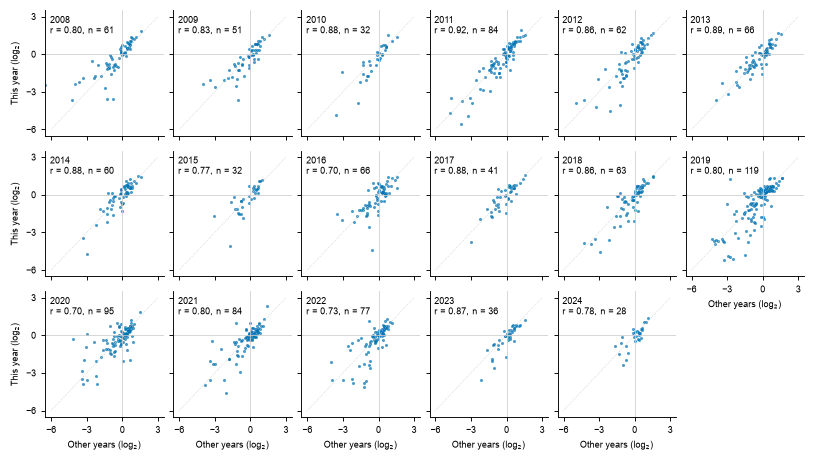

In [8]:
# S3 Fig: every year against the other years (N2), one panel per year
z = np.load(AGG / "null_N2.npz"); Oy = z["observed_year"].astype(float); C = z["counts"].astype(float); Ey = C.mean(0); sdy = C.std(0, ddof=1)
elig = np.load(AGG / "eligible_primary.npy"); lr = lambda O, E: np.log2((O + .5) / (E + .5))
fig, axes = plt.subplots(3, 6, figsize=(7.5, 4.2), sharex=True, sharey=True, gridspec_kw={"wspace": 0.08, "hspace": 0.12})
rows = []
for ti, (yr, ax) in enumerate(zip(YEARS, axes.ravel())):
    Or, Er = Oy.sum(0) - Oy[ti], Ey.sum(0) - Ey[ti]; sdr = (C.sum(1) - C[:, ti, :]).std(0, ddof=1)
    m = elig & (Ey[ti] >= 5) & (Er >= 5) & (sdy[ti] > 0) & (sdr > 0)
    a, b = lr(Or, Er)[m], lr(Oy[ti], Ey[ti])[m]
    ax.axhline(0, color="#CCCCCC", lw=0.5); ax.axvline(0, color="#CCCCCC", lw=0.5)
    ax.plot([-6, 3], [-6, 3], color="#CCCCCC", lw=0.5, ls=":")
    ax.scatter(a, b, s=4, color=OI["blue"], alpha=0.7, lw=0)
    ax.text(0.04, 0.96, f"{yr}\nr = {np.corrcoef(a, b)[0, 1]:.2f}, n = {m.sum()}", transform=ax.transAxes, va="top", fontsize=6)
    rows += [{"year": yr, "code_i": PAIRS[h, 0], "code_j": PAIRS[h, 1], "rest": lr(Or, Er)[h], "year_value": lr(Oy[ti], Ey[ti])[h]} for h in np.where(m)[0]]
axes.ravel()[-1].axis("off"); axes[1, -1].xaxis.set_tick_params(labelbottom=True)
fig.subplots_adjust(left=0.07, right=0.99, bottom=0.1, top=0.98)
for ax in list(axes[-1, :-1]) + [axes[1, -1]]:
    ax.set_xlabel("Other years (log$_2$)", fontsize=6)
for ax in axes[:, 0]:
    ax.set_ylabel("This year (log$_2$)", fontsize=6)
ax.set_xlim(-6.5, 3.5); ax.set_ylim(-6.5, 3.5); ax.set_xticks([-6, -3, 0, 3]); ax.set_yticks([-6, -3, 0, 3])
export_source_table(pd.DataFrame(rows), "S3_year_vs_rest_scatter_N2.csv")
save(fig, "S3_Fig")

S4_Fig layout check: ok
saved S4_Fig


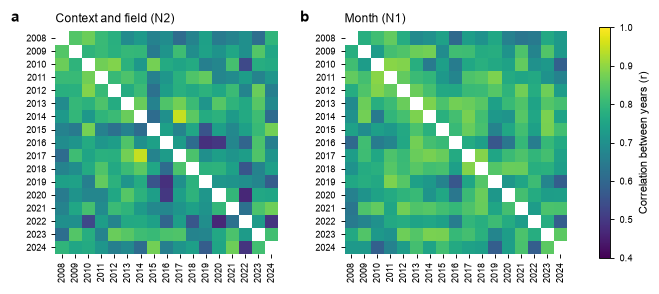

In [9]:
# S4 Fig: year-by-year correlation matrices
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4), gridspec_kw={"wspace": 0.3})
for ax, name, letter in zip(axes, ["N2", "N1"], "ab"):
    Mx = pd.read_csv(TAB / f"year_by_year_pearson_{name}.csv", index_col=0)
    im = ax.imshow(Mx.to_numpy(), vmin=0.4, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(YEARS)), YEARS, rotation=90); ax.set_yticks(range(len(YEARS)), YEARS)
    ax.set_title(REF_LABEL[name], fontsize=8, loc="left")
    for s in ax.spines.values():
        s.set_visible(False)
    panel_letter(ax, letter, x=-0.2)
cb = fig.colorbar(im, ax=axes, shrink=0.8); cb.set_label("Correlation between years (r)", fontsize=7)
save(fig, "S4_Fig")

S5_Fig layout check: ok
saved S5_Fig


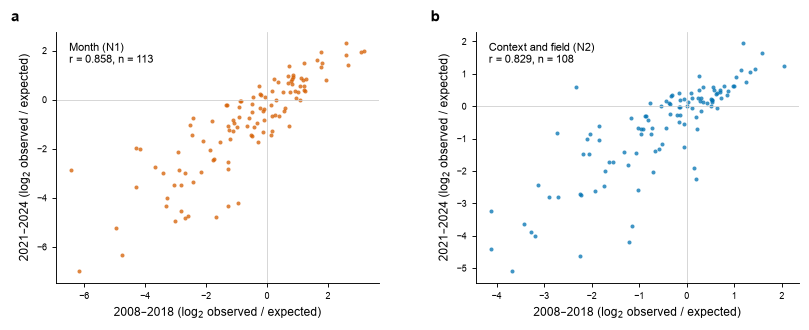

In [10]:
# S5 Fig: the pilot's two windows reproduced (2008-2018 vs 2021-2024)
elig_p = np.load(AGG / "eligible_pilot_frozen.npy")
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.0), gridspec_kw={"wspace": 0.3})
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.16, top=0.92)
rows = []
for ax, name, letter in zip(axes, ["N1", "N2"], "ab"):
    z = np.load(AGG / f"null_{name}.npz"); Oy = z["observed_year"].astype(float); C = z["counts"].astype(float)
    a_idx, b_idx = YEARS <= 2018, YEARS >= 2021
    Oa, Ea, Ob, Eb = Oy[a_idx].sum(0), C[:, a_idx].sum(1).mean(0), Oy[b_idx].sum(0), C[:, b_idx].sum(1).mean(0)
    sda, sdb = C[:, a_idx].sum(1).std(0, ddof=1), C[:, b_idx].sum(1).std(0, ddof=1)
    m = elig_p & (Ea >= 5) & (Eb >= 5) & (sda > 0) & (sdb > 0)
    x, y = lr(Oa, Ea)[m], lr(Ob, Eb)[m]
    ax.axhline(0, color="#CCCCCC", lw=0.5); ax.axvline(0, color="#CCCCCC", lw=0.5)
    ax.scatter(x, y, s=7, color=REF_COLOR[name], alpha=0.75, lw=0)
    ax.set_xlabel("2008–2018 (log$_2$ observed / expected)"); ax.set_ylabel("2021–2024 (log$_2$ observed / expected)")
    ax.text(0.04, 0.96, f"{REF_LABEL[name]}\nr = {np.corrcoef(x, y)[0, 1]:.3f}, n = {m.sum()}", transform=ax.transAxes, va="top", fontsize=7)
    rows += [{"reference": name, "code_i": PAIRS[h, 0], "code_j": PAIRS[h, 1], "w2008_2018": lr(Oa, Ea)[h], "w2021_2024": lr(Ob, Eb)[h]} for h in np.where(m)[0]]
    panel_letter(ax, letter)
export_source_table(pd.DataFrame(rows), "S5_pilot_windows.csv")
save(fig, "S5_Fig")

S6_Fig layout check: ok
saved S6_Fig


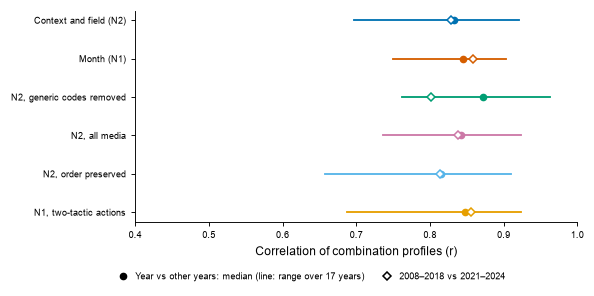

In [11]:
# S6 Fig: robustness across references (median and range of year-vs-rest r; pilot windows)
yvr = pd.read_csv(TAB / "annual_year_vs_rest.csv"); pil = pd.read_csv(TAB / "pilot_windows_reproduced.csv").set_index("reference")
refs = ["N2", "N1", "N2_clean", "N2_allmedia", "N2_order", "N1_k2"]
fig, ax = plt.subplots(figsize=(6.0, 3.0))
fig.subplots_adjust(left=0.3, right=0.97, bottom=0.33, top=0.97)
for i, r in enumerate(refs):
    z = yvr[yvr.reference == r]
    ax.plot([z.pearson.min(), z.pearson.max()], [i, i], color=REF_COLOR[r], lw=1.2)
    ax.plot(z.pearson.median(), i, "o", color=REF_COLOR[r], ms=4)
    ax.plot(pil.loc[r, "pearson"], i, "D", mfc="white", mec=REF_COLOR[r], ms=4)
ax.set_yticks(range(len(refs)), [REF_LABEL[r] for r in refs]); ax.invert_yaxis()
ax.set_xlabel("Correlation of combination profiles (r)"); ax.set_xlim(0.4, 1)
ax.plot([], [], "o", color="k", ms=4, label="Year vs other years: median (line: range over 17 years)")
ax.plot([], [], "D", mfc="white", mec="k", ms=4, label="2008–2018 vs 2021–2024")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2, fontsize=6, handlelength=1)
export_source_table(yvr, "S6_robustness.csv")
save(fig, "S6_Fig")